# **Homework 6**
Name: Maddox Guthrie \
Id: 12184185

# 1.1 Exercise 1: The power method and its convergence rate
Let $A$ be an $n \times n$ matrix with a **dominant eigenvalue**, that is,
$$
|\lambda_1| \gt |\lambda_2| \ge \cdots \ge |\lambda_n|.
$$
Pick a random starting vector $x_0 \ne 0$, normalize it so that $\|x_0\| = 1$, and repeat for $k = 0, 1, 2, \ldots$
$$
y_{k+1} = Ax_k, \quad x_{k+1} = \frac{y_{k+1}}{\|y_{k+1}\|}
$$
Then (for almost every $𝑥_0$)
- $x_k$ converges (up to sign) to a unit eigenvector $v_1$ associated with $\lambda_1$,
- the Rayleigh quotient $\mu_k = x_k^T Ax_k$ converges to $\lambda_1$.

The residual $r_k = \|Ax_k - \mu_kx_k\|$ measures how close $(\mu_k, x_k)$ is to being an eigenpair, and it decays
like $O(|\frac{\lambda_2}{\lambda_1}|^k)$.

## 1.1.1 Part 1: Implement the power method

In [1]:
import numpy as np

In [2]:
def power_method(A, x0, tol=1e-10, max_iters=1000):
    x = x0 / np.linalg.norm(x0)
    errors = []
    converged = False
    lamb = None
    for i in range(max_iters):
        y = A @ x
        lamb = x @ y
        err = np.linalg.norm(y - lamb * x)
        errors.append(err)
        if err < tol:
            converged = True
            print(f"Algorithm converges at step {i+1}th")
            break

        y_norm = np.linalg.norm(y)
        if y_norm == 0:
            break

        x = y / y_norm

    return lamb, x, converged, errors

## 1.1.2 Part 2: Test cases

1. **Random integer matrix.** Use `np.random.randint` to create a random $4 \times 4$ matrix with integer entries (for example, between −5 and 5). Run `power_method` with a random `x0`. Compare your `lamb` with the eigenvalue of largest magnitude from `np.linalg.eigvals`, and check that `A @ x` is close to `lamb * x` using `np.allclose`. If the random matrix happens to have no single dominant eigenvalue (for example, a complex-conjugate pair of largest magnitude), say so and generate another matrix.

In [3]:
A = np.random.randint(low=-5, high=5, size=(4, 4))
x0 = np.random.randn(4)
lamb, x, converged, errors = power_method(A, x0)

Algorithm converges at step 81th


In [4]:
eigen_vals = np.linalg.eigvals(A)
print(f"lamb == dominant: {np.isclose(lamb, eigen_vals[np.argmax(np.abs(eigen_vals))])}")
print(f"A @ x == lamb * x: {np.allclose(A @ x, lamb * x)}")

lamb == dominant: True
A @ x == lamb * x: True


If this ever prints False, it's because that random matrix had no single dominant eigenvalue, so the power method can't converge. In that case I just regenerate the matrix by running the 2 previous cells again.

2. **A matrix with prescribed eigenvalues.** Write a function
`gen_dominant_matrix(values)` that
- takes a list of $n$ numbers values,
- builds the diagonal matrix $D$ with `values` on the diagonal,
- generates a random $n \times n$ matrix $P$ with standard normal entries (`np.random.normal`), which is invertible with probability 1,
- returns $PDP^{−1}$ (use `np.linalg.inv`).

The returned matrix has eigenvalues exactly values. Check this with `np.linalg.eigvals`.

In [5]:
def gen_dominant_matrix(values):
    n = len(values)
    D = np.zeros((n,n))
    for i in range(n):
        for j in range(n):
            if i == j:
                D[i, j] = values[i]

    P = np.random.normal(size=(n,n))

    return P @ D  @ np.linalg.inv(P)

In [6]:
values = [2, -3, 6, -1]
eigen_vals = np.linalg.eigvals(gen_dominant_matrix(values))
values.sort()
eigen_vals.sort()
np.allclose(values, eigen_vals)

True

3. Use `gen_dominant_matrix([3, 2, 1, -1])` to create a $4 \times 4$ matrix and test your `power_method`. Confirm that `lamb` is close to 3 and print the number of iterations used.

In [7]:
A = gen_dominant_matrix([3, 2, 1, -1])
x0 = np.random.randn(4)
lamb, x, converged, errors = power_method(A, x0)
print(f"lamb == 3: {np.isclose(lamb, 3)}")

Algorithm converges at step 62th
lamb == 3: True


## 1.1.3 Part 3: Convergence rate
The theory says the residual behaves like $C|\lambda_2/\lambda_1|^k$ for some constant $C$. In this part you compare the experimental residuals with this prediction.

1. Use gen_dominant_matrix to create two matrices:
- $A_1$ with eigenvalues [3, 2, 1, −1], so $|\lambda_2/\lambda_1| = 2/3$,
- $A_2$ with eigenvalues [2.1, 2, 1, −1], so $|\lambda_2/\lambda_1| = 2/2.1 \approx 0.95$.

In [8]:
A1 = gen_dominant_matrix([3, 2, 1, -1])
A2 = gen_dominant_matrix([2.1, 2, 1, -1])

2. For each matrix, run `power_method` with `tol=1e-10` and a large enough `max_iters` (for example, 5000), starting from the same `x0`. Record the eigenvalue, the eigenvector, and the list of residuals.

In [9]:
x0 = np.random.randn(4)
lamb1, x1, converged1, errors1 = power_method(A1, x0, tol=1e-10, max_iters=5000)
lamb2, x2, converged2, errors2 = power_method(A2, x0, tol=1e-10, max_iters=5000)

Algorithm converges at step 59th
Algorithm converges at step 438th


3. For each matrix, make one plot (two plots in total) with the iteration number $k$ on the horizontal axis and the residual on a **logarithmic** vertical axis (`ax.semilogy`). On each plot show
- the experimental residuals (as markers or a line),
- the theoretical curve $C|\lambda_2/\lambda_1|^k$ (as a dashed line). Choose $C$ so that the curve starts near the experimental data, for example by fitting log(residual$_𝑘$) with `np.polyfit` or by matching the first residual.

Label the axes, add a title and a legend.

In [10]:
import matplotlib.pyplot as plt

In [11]:
ratio1 = 2 / 3
ratio2 = 2 / 2.1

k_vals_1 = np.arange(1, len(errors1) + 1)
k_vals_2 = np.arange(1, len(errors2) + 1)

_, intercept1 = np.polyfit(k_vals_1, np.log(errors1), deg=1)
_, intercept2 = np.polyfit(k_vals_2, np.log(errors2), deg=1)

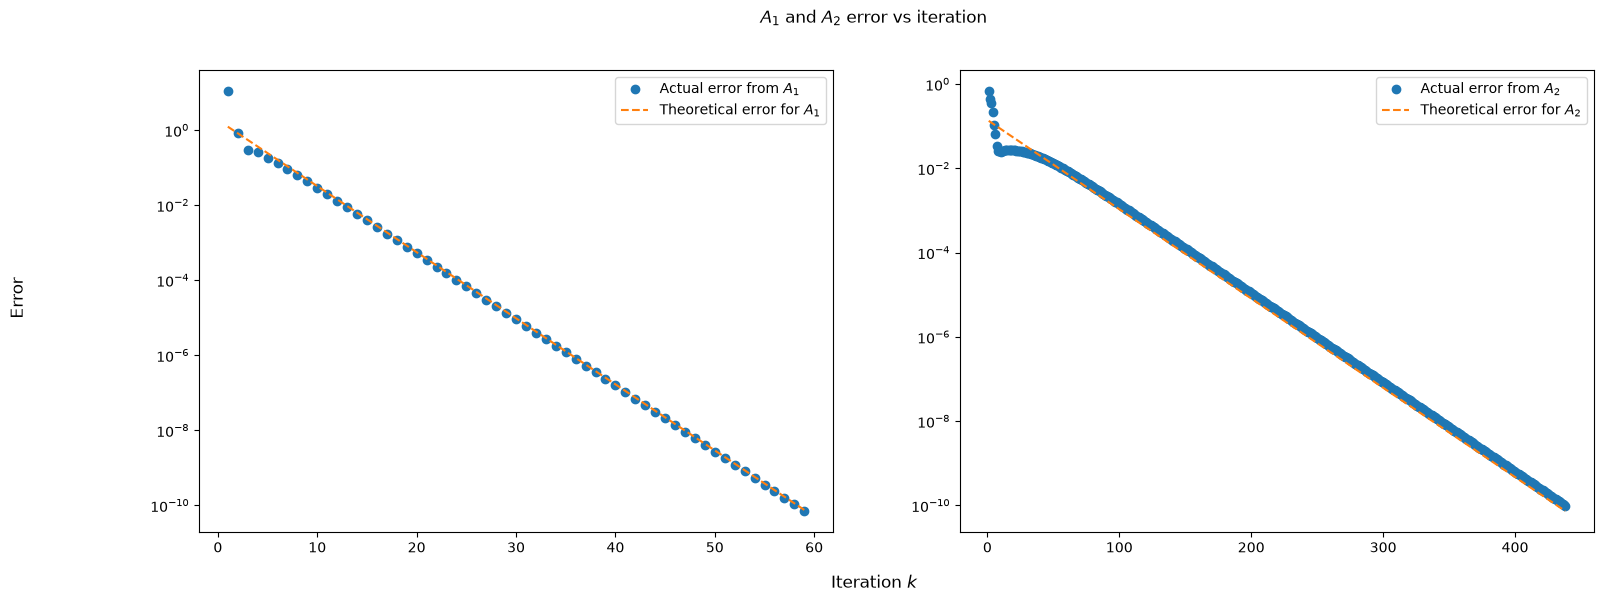

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(18, 6))

k_vals_1 = np.arange(1, len(errors1) + 1)
axs[0].semilogy(k_vals_1, errors1, "o", label=r"Actual error from $A_1$")
axs[0].semilogy(k_vals_1, np.exp(intercept1) * ratio1**k_vals_1, "--", label=r"Theoretical error for $A_1$")

k_vals_2 = np.arange(1, len(errors2) + 1)
axs[1].semilogy(k_vals_2, errors2, "o", label="Actual error from $A_2$")
axs[1].semilogy(k_vals_2, np.exp(intercept2) * ratio2**k_vals_2, "--", label="Theoretical error for $A_2$")

fig.suptitle(r"$A_1$ and $A_2$ error vs iteration")
fig.supxlabel(r"Iteration $k$")
fig.supylabel("Error")
axs[0].legend()
axs[1].legend()

plt.show()

4. In a Markdown cell, write one paragraph (4 to 6 sentences) that explains
- what the plots show about the experimental versus the theoretical slopes,
- why a straight line appears on a semilog plot,
- why the second matrix needs many more iterations than the first one, in terms of the ratio $|\lambda_2/\lambda_1|$.

Both plots show the actual error falling along a straight line that sits almost exactly on top of the theoretical line. The experimental slope matches the theoretical slope, apart from the first few iterations where the error hasn’t settled into its steady rate yet.

A straight line shows up on a semilog plot because the error behaves like $error(k) = C \cdot r^k$, where $r = \frac{|\lambda_2|}{|\lambda_1|}$ and taking the log gives $\log(error(k)) = \log(C) + k \cdot \log(r)$, which is linear in $k$ with slope $\log(r)$. The ratio $r$ is the convergence rate, and a smaller $r$ means the error shrinks faster each step, giving a steeper line.

For $A_1$ the ratio is $2/3 \approx 0.67$ and the line drops about 10 orders of magnitude in about 55 iterations, while $A_2$ has a ratio of $2/2.1 \approx 0.95$ and needs about 400 iterations to drop the same amount. Since the number of iterations needed to reach a tolerance is about $\log(tol) / \log(r)$, a ratio near 1 makes $\log(r)$ tiny and the iteration count large, which is why the second matrix takes so many more steps.

## 1.1.4 Part 4: A larger matrix (rdb200.npy)
You are provided the file `rdb200.npy`, a $200 \times 200$ matrix. Put it in the same folder as your notebook and load it with `np.load("rdb200.npy")`.

In [13]:
A = np.load("rdb200.npy")

1. Use np.linalg.eigvals to get all eigenvalues of this matrix, sort them by magnitude, and compute the ratio $|\lambda_2/\lambda_1|$. Print it.

In [14]:
eigen_vals = np.linalg.eigvals(A)
sorted_idx = np.argsort(np.abs(eigen_vals), descending=True)
sorted_eigen_vals = eigen_vals[sorted_idx]
ratio = np.abs(sorted_eigen_vals[1] / sorted_eigen_vals[0])
print(ratio)

0.9719529311911073


2. Run your `power_method` on this matrix with a random `x0` (`np.random.normal(size=200)`), `tol=1e-10`, and a large enough `max_iters`. Report the dominant eigenvalue, whether it converged, and the number of iterations.

In [15]:
x0 = np.random.normal(size=200)
lamb, x, converged, errors = power_method(A, x0, tol=1e-10, max_iters=5000)
print(f"Dominant Eigenvalue: {lamb}")

Algorithm converges at step 837th
Dominant Eigenvalue: -33.386679970364206


3. Plot the experimental residuals and the theoretical curve $C|\frac{\lambda_2}{\lambda_1}|^k$ on a semilog plot, as in Part 3.

In [16]:
k_vals = np.arange(1, len(errors) + 1)
_, intercept = np.polyfit(k_vals, np.log(errors), deg=1)

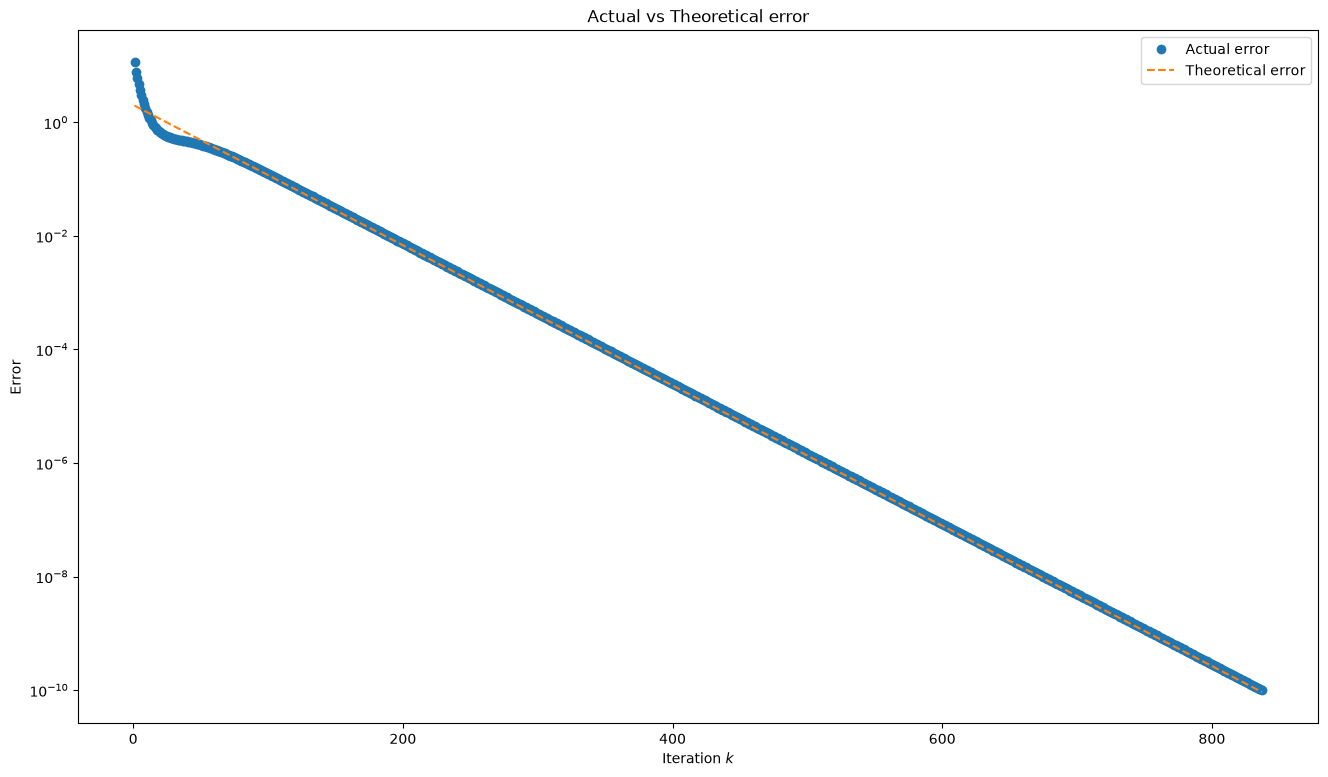

In [17]:
fig, ax = plt.subplots(figsize=(16, 9))

ax.semilogy(k_vals, errors, "o", label="Actual error")
ax.semilogy(k_vals, np.exp(intercept) * ratio**k_vals, "--", label="Theoretical error")

plt.title("Actual vs Theoretical error")
plt.xlabel(r"Iteration $k$")
plt.ylabel("Error")
plt.legend()

plt.show()

4. In a Markdown cell, write two or three sentences comparing the experimental and theoretical rates for this matrix, and explain how the number of iterations relates to the ratio you computed.

The experimental convergence rate matches the theoretical rate, since the error decreases at about the ratio $|\frac{\lambda_2}{\lambda_1}| \approx 0.972$, which makes the log-error line fall with slope $\log(0.972)$. Because this ratio is so close to 1, the error only shrinks by about 3% per iteration, so reaching a tolerance of 1e-10 took roughly 850 iterations. In general the iteration count is about $\log(\text{tol}) / \log(r)$, so the closer the ratio is to 1, the more iterations the power method needs.

# 1.2 Exercise 2: SVD Implementation from Scratch

## 1.2.1 Objective:
This exercise will help students understand the Singular Value Decomposition (SVD) algorithm by implementing it from scratch. Students are only allowed to use `np.linalg.eig` to compute eigenvalues and eigenvectors. Using `np.linalg.svd` is not permitted.

## 1.2.2 Instructions

1. Task: Implement a function that computes the SVD of any given matrix $A$. Recall that $SVD$ decomposes a matrix $A$ as:

$$
A = U \Sigma V^T
$$

where $U$ and $V$ are orthogonal matrices, and $\Sigma$ is a diagonal matrix containing singular values

In [18]:
def svd_form(a):
    m, n = a.shape
    L = a @ a.T
    leigen_vals, leigen_vecs = np.linalg.eig(L)
    leigen_vals = leigen_vals.real
    left_idx = np.argsort(-leigen_vals)
    sorted_vals = leigen_vals[left_idx]
    U = leigen_vecs[:, left_idx]
    S = np.zeros_like(a).astype(float)
    for i in range(min(m,n)):
        S[i,i] = np.sqrt(sorted_vals[i])

    R = a.T @ a
    reigen_vals, reigen_vecs = np.linalg.eig(R)
    reigen_vals = reigen_vals.real
    right_idx = np.argsort(-reigen_vals)
    sorted_right_vecs = reigen_vecs[:, right_idx]
    vectors = []
    for i in range(n):
        v_i = sorted_right_vecs[:, i]
        if i < m:
            u_i = U[:, i]
            s_i = S[i, i]
            if np.allclose(a.T@u_i, s_i*v_i):
                vectors.append(v_i)
            else:
                vectors.append(-v_i)
        else:
            vectors.append(v_i)

    return U, S, np.array(vectors)

2. Testing: Validate your implementation using different types of matrices, including:
- Square matrices
- Rectangular matrices where $m \gt n$ and $m \lt n$.

In [19]:
a = np.random.randint(low=-3, high=3, size=(20, 20))
u, s, vt = svd_form(a)
np.allclose(a, u @ (s @ vt))

True

In [20]:
b = np.random.randint(low=-3, high=3, size=(25, 10))
u, s, vt = svd_form(b)
np.allclose(b, u @ (s @ vt))

True

In [21]:
c = np.random.randint(low=-3, high=3, size=(10, 25))
u, s, vt = svd_form(c)
np.allclose(c, u @ (s @ vt))

True